In [1]:
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt 


In [2]:
df = pd.read_excel('/Users/rokiialaa/Downloads/Telco_customer_churn.xlsx')

In [3]:
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [4]:
df.shape   

(7043, 33)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

In [6]:
df.isnull().sum()

CustomerID              0
Count                   0
Country                 0
State                   0
City                    0
Zip Code                0
Lat Long                0
Latitude                0
Longitude               0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges           0
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64

In [7]:
df['Churn Reason'].unique() # sentiment analysis 

array(['Competitor made better offer', 'Moved',
       'Competitor had better devices',
       'Competitor offered higher download speeds',
       'Competitor offered more data', 'Price too high',
       'Product dissatisfaction', 'Service dissatisfaction',
       'Lack of self-service on Website', 'Network reliability',
       'Limited range of services',
       'Lack of affordable download/upload speed',
       'Long distance charges', 'Extra data charges', "Don't know",
       'Poor expertise of online support',
       'Poor expertise of phone support', 'Attitude of service provider',
       'Attitude of support person', 'Deceased', nan], dtype=object)

In [8]:
df['Count'].unique() #not useful
df['Country'].unique() #not useful all US
df['State'].unique() #not useful all California
#lat long not useful
#ZIP not useful

array(['California'], dtype=object)

In [9]:
df['Churn Label'].unique() # useful
df['Churn Label'].value_counts() # useful  biased

Churn Label
No     5174
Yes    1869
Name: count, dtype: int64

In [10]:
df.duplicated().sum() 

np.int64(0)

In [11]:
df['Churn Value'].unique() # useful
df['Churn Value'].value_counts() # useful biased

Churn Value
0    5174
1    1869
Name: count, dtype: int64

In [12]:

#drop not useful columns
df.drop(columns=['Count','CustomerID','Churn Label', 'Country', 'State', 'Zip Code'], inplace=True)



In [13]:
df.describe()

,Latitude,Longitude,Tenure Months,Monthly Charges,Churn Value,Churn Score,CLTV
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,36.282441,-119.798880,32.371149,64.761692,0.265370,58.699418,4400.295755
std,2.455723,2.157889,24.559481,30.090047,0.441561,21.525131,1183.057152
min,32.555828,-124.301372,0.000000,18.250000,0.000000,5.000000,2003.000000
25%,34.030915,-121.815412,9.000000,35.500000,0.000000,40.000000,3469.000000
50%,36.391777,-119.730885,29.000000,70.350000,0.000000,61.000000,4527.000000
75%,38.224869,-118.043237,55.000000,89.850000,1.000000,75.000000,5380.500000
max,41.962127,-114.192901,72.000000,118.750000,1.000000,100.000000,6500.000000


In [14]:
df['City'].unique() # useful
df['City'].value_counts() # useful
#too many cities, group by 4 regions north south east west



City
Los Angeles       305
San Diego         150
San Jose          112
Sacramento        108
San Francisco     104
                 ... 
Healdsburg          4
Jenner              4
Philo               4
Point Arena         4
Olympic Valley      4
Name: count, Length: 1129, dtype: int64

In [15]:
df['Gender'].unique() # useful
df['Gender'].value_counts()

Gender
Male      3555
Female    3488
Name: count, dtype: int64

In [16]:
df['Senior Citizen'].unique() # useful
df['Senior Citizen'].value_counts() 




Senior Citizen
No     5901
Yes    1142
Name: count, dtype: int64

In [17]:
df['Partner'].unique() # useful
df['Partner'].value_counts() 

Partner
No     3641
Yes    3402
Name: count, dtype: int64

In [18]:
df['Dependents'].unique() #useful
df['Dependents'].value_counts()

Dependents
No     5416
Yes    1627
Name: count, dtype: int64

In [19]:
from sklearn.model_selection import train_test_split

y= df['Churn Value']
X = df.drop(columns=['Churn Value', 'Churn Score', 'Churn Reason'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [20]:
X_train.head()

,City,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,...,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,CLTV
2142,San Diego,"32.802959, -117.027095",32.802959,-117.027095,Male,No,Yes,No,71,Yes,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),98.65,6962.85,5101
1623,Jamestown,"37.84771, -120.486589",37.847710,-120.486589,Female,No,No,No,16,Yes,...,Yes,No,No,Yes,Month-to-month,Yes,Credit card (automatic),93.20,1573.7,5497
6074,Littlerock,"34.505273, -117.955054",34.505273,-117.955054,Female,No,No,No,32,Yes,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),104.05,3416.85,2335
1362,El Monte,"34.079934, -118.046695",34.079934,-118.046695,Female,Yes,Yes,No,24,No,...,Yes,No,No,Yes,Month-to-month,Yes,Credit card (automatic),40.65,933.3,3843
6754,Los Angeles,"33.988543, -118.334081",33.988543,-118.334081,Female,No,Yes,Yes,20,Yes,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.05,406.05,2698


In [21]:
X_train.info()


<class 'pandas.core.frame.DataFrame'>
Index: 5634 entries, 2142 to 860
Data columns (total 24 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   City               5634 non-null   object 
 1   Lat Long           5634 non-null   object 
 2   Latitude           5634 non-null   float64
 3   Longitude          5634 non-null   float64
 4   Gender             5634 non-null   object 
 5   Senior Citizen     5634 non-null   object 
 6   Partner            5634 non-null   object 
 7   Dependents         5634 non-null   object 
 8   Tenure Months      5634 non-null   int64  
 9   Phone Service      5634 non-null   object 
 10  Multiple Lines     5634 non-null   object 
 11  Internet Service   5634 non-null   object 
 12  Online Security    5634 non-null   object 
 13  Online Backup      5634 non-null   object 
 14  Device Protection  5634 non-null   object 
 15  Tech Support       5634 non-null   object 
 16  Streaming TV       5634 non

In [22]:
print(type(X_train['Total Charges'].iloc[0])) 
X_train['Total Charges'] = X_train['Total Charges'].replace(r'^\s*$', np.nan, regex=True)
X_train['Total Charges'] = X_train['Total Charges'].astype(float)


<class 'float'>


/var/folders/nd/rgq9d99j35x4ykbz3pyy4c2r0000gn/T/ipykernel_11443/3235118626.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_train['Total Charges'] = X_train['Total Charges'].replace(r'^\s*$', np.nan, regex=True)


In [23]:
X_train.info()


<class 'pandas.core.frame.DataFrame'>
Index: 5634 entries, 2142 to 860
Data columns (total 24 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   City               5634 non-null   object 
 1   Lat Long           5634 non-null   object 
 2   Latitude           5634 non-null   float64
 3   Longitude          5634 non-null   float64
 4   Gender             5634 non-null   object 
 5   Senior Citizen     5634 non-null   object 
 6   Partner            5634 non-null   object 
 7   Dependents         5634 non-null   object 
 8   Tenure Months      5634 non-null   int64  
 9   Phone Service      5634 non-null   object 
 10  Multiple Lines     5634 non-null   object 
 11  Internet Service   5634 non-null   object 
 12  Online Security    5634 non-null   object 
 13  Online Backup      5634 non-null   object 
 14  Device Protection  5634 non-null   object 
 15  Tech Support       5634 non-null   object 
 16  Streaming TV       5634 non

/var/folders/nd/rgq9d99j35x4ykbz3pyy4c2r0000gn/T/ipykernel_11443/3866647717.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Tenure Months', data=X_train, palette='viridis')


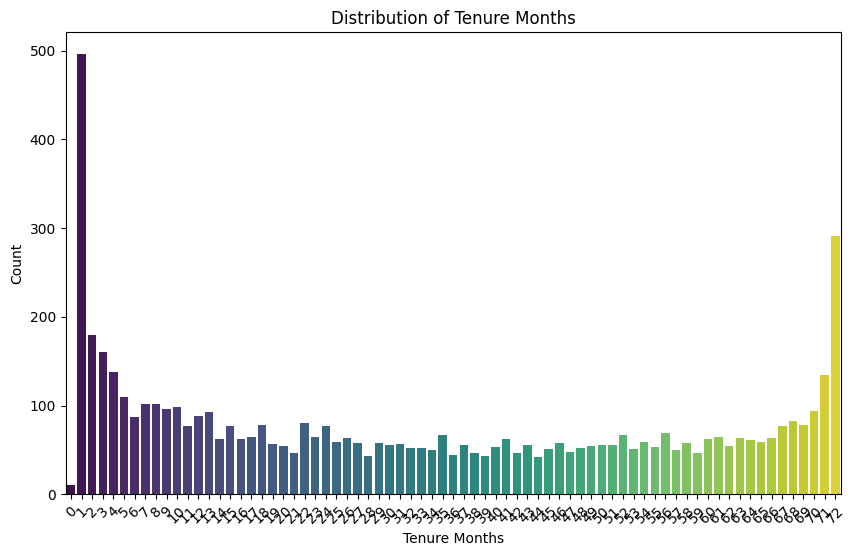

In [24]:
#plot tenure months
plt.figure(figsize=(10, 6))
sns.countplot(x='Tenure Months', data=X_train, palette='viridis')
plt.title('Distribution of Tenure Months')
plt.xlabel('Tenure Months')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

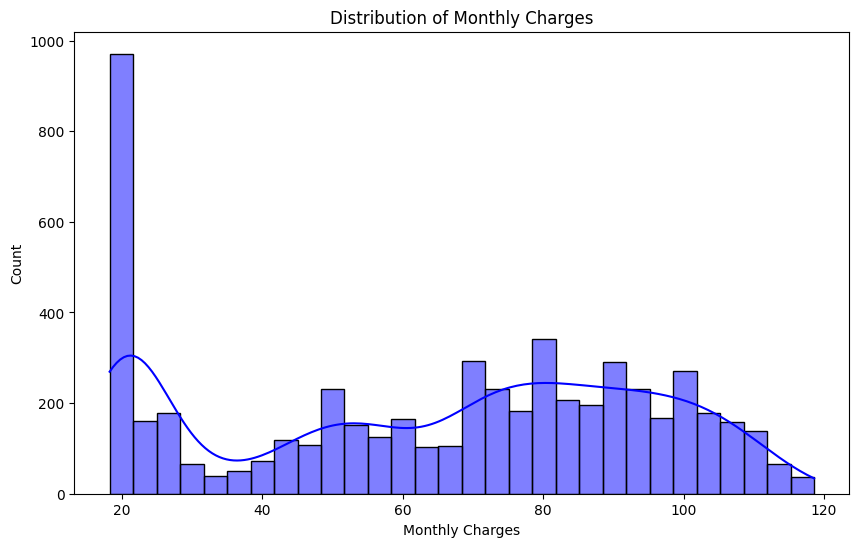

In [25]:
#plot monthly charges
plt.figure(figsize=(10, 6))
sns.histplot(X_train['Monthly Charges'], bins=30, kde=True, color='blue')
plt.title('Distribution of Monthly Charges')    
plt.xlabel('Monthly Charges')
plt.ylabel('Count')
plt.show()    

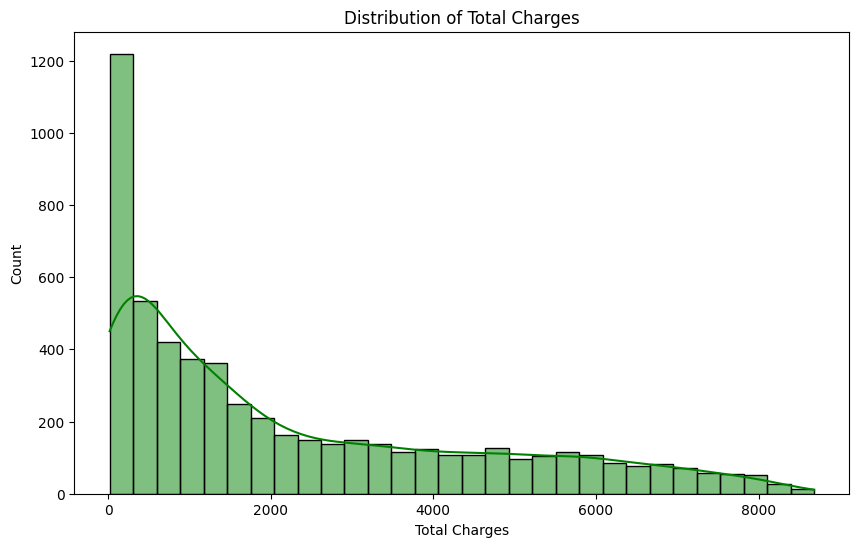

In [26]:
#plotting the distribution of Total Charges
plt.figure(figsize=(10, 6))
sns.histplot(X_train['Total Charges'], bins=30, kde=True, color='green')
plt.title('Distribution of Total Charges')
plt.xlabel('Total Charges')
plt.ylabel('Count')
plt.show()

In [27]:
#preprocessing pipeline
#split categorical and numerical features
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer



Features [4-7]

In [30]:
#Categorical features
cat_features = X_train.select_dtypes(include=['object']).columns.tolist()
cat_features.remove('City') 
cat_features.remove('Lat Long')
print("Categorical features:", cat_features)
# Numerical features
num_features = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
num_features.remove('Latitude')
num_features.remove('Longitude')
print("Numerical features:", num_features)

Categorical features: ['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']
Numerical features: ['Tenure Months', 'Monthly Charges', 'Total Charges', 'CLTV']


/var/folders/nd/rgq9d99j35x4ykbz3pyy4c2r0000gn/T/ipykernel_11443/3957059429.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=feature, data=X_train, palette='viridis')


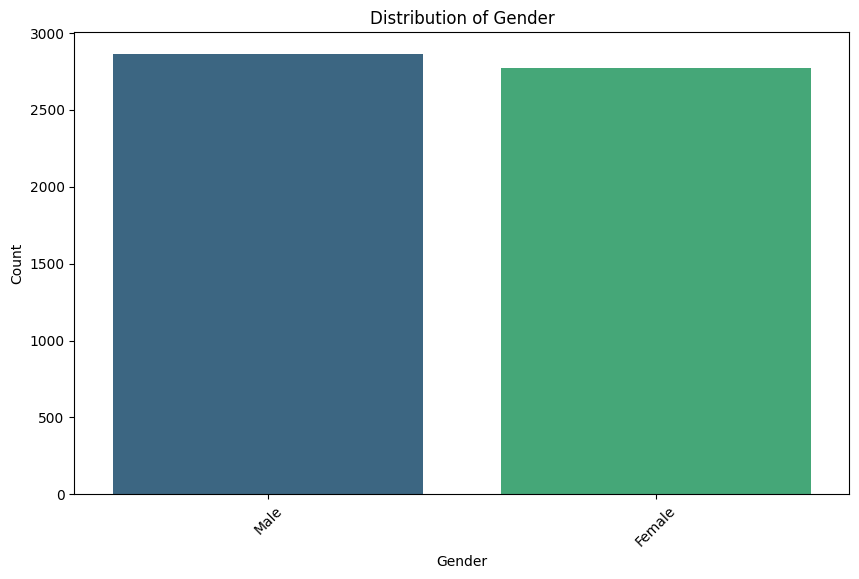

/var/folders/nd/rgq9d99j35x4ykbz3pyy4c2r0000gn/T/ipykernel_11443/3957059429.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=feature, data=X_train, palette='viridis')


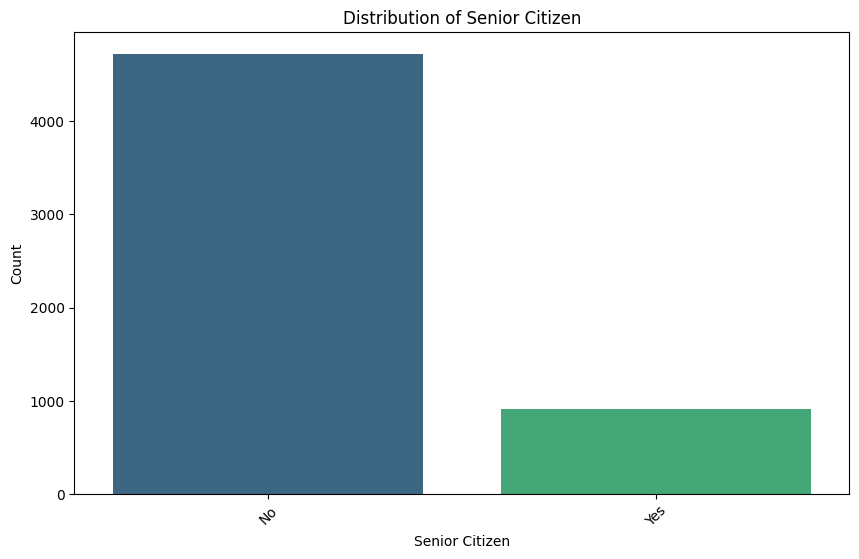

/var/folders/nd/rgq9d99j35x4ykbz3pyy4c2r0000gn/T/ipykernel_11443/3957059429.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=feature, data=X_train, palette='viridis')


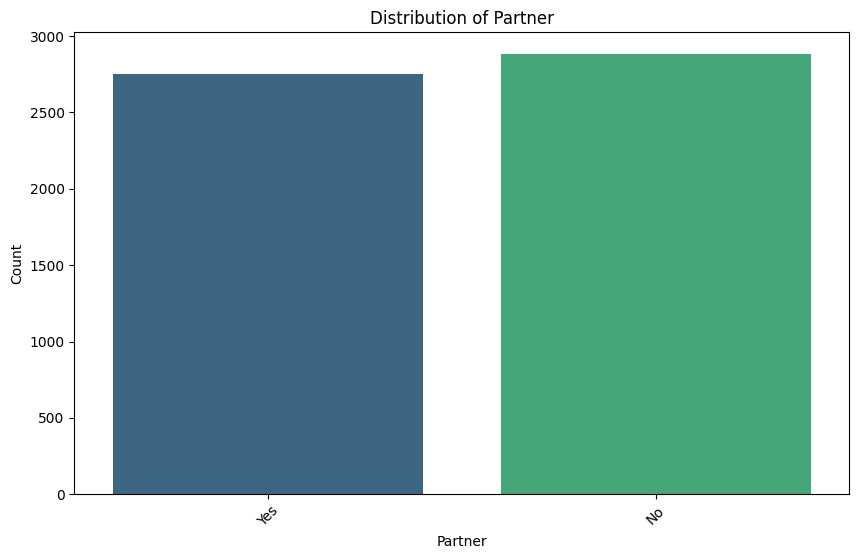

/var/folders/nd/rgq9d99j35x4ykbz3pyy4c2r0000gn/T/ipykernel_11443/3957059429.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=feature, data=X_train, palette='viridis')


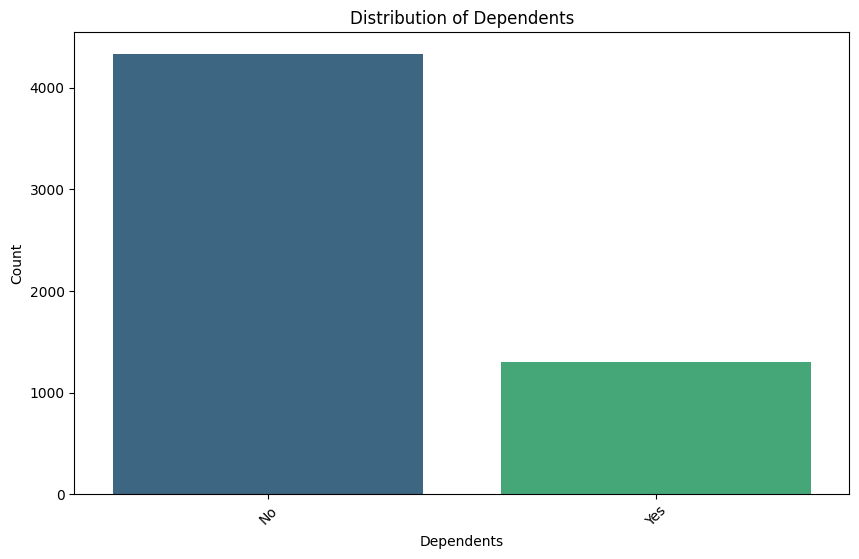

/var/folders/nd/rgq9d99j35x4ykbz3pyy4c2r0000gn/T/ipykernel_11443/3957059429.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=feature, data=X_train, palette='viridis')


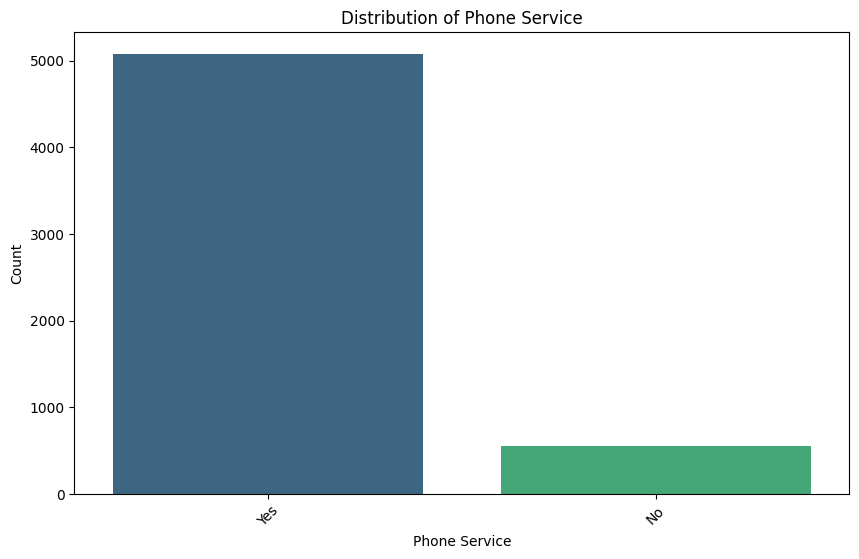

/var/folders/nd/rgq9d99j35x4ykbz3pyy4c2r0000gn/T/ipykernel_11443/3957059429.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=feature, data=X_train, palette='viridis')


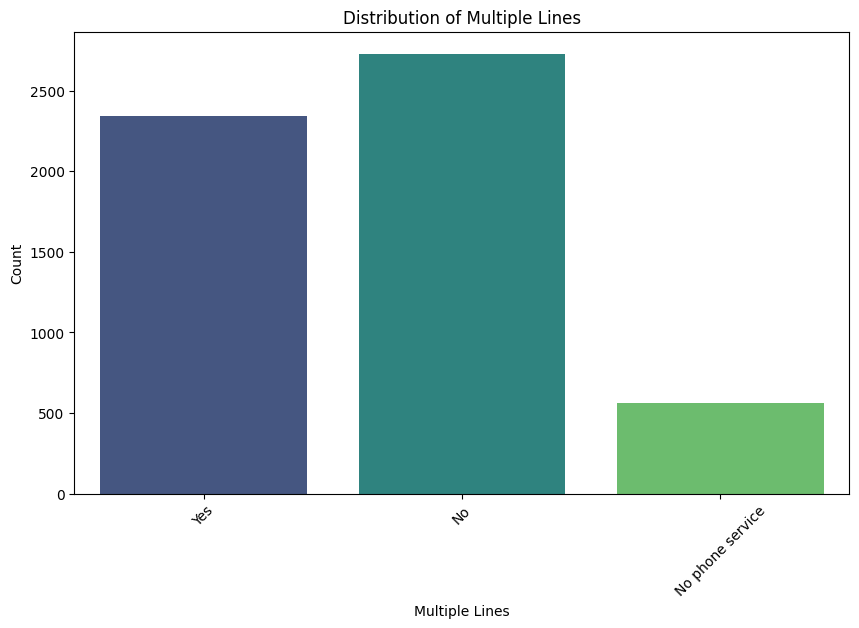

/var/folders/nd/rgq9d99j35x4ykbz3pyy4c2r0000gn/T/ipykernel_11443/3957059429.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=feature, data=X_train, palette='viridis')


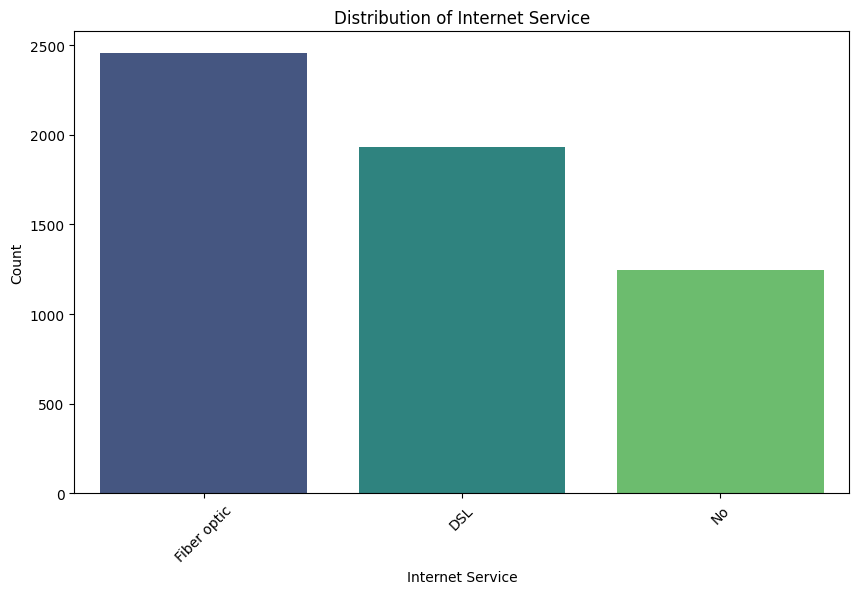

/var/folders/nd/rgq9d99j35x4ykbz3pyy4c2r0000gn/T/ipykernel_11443/3957059429.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=feature, data=X_train, palette='viridis')


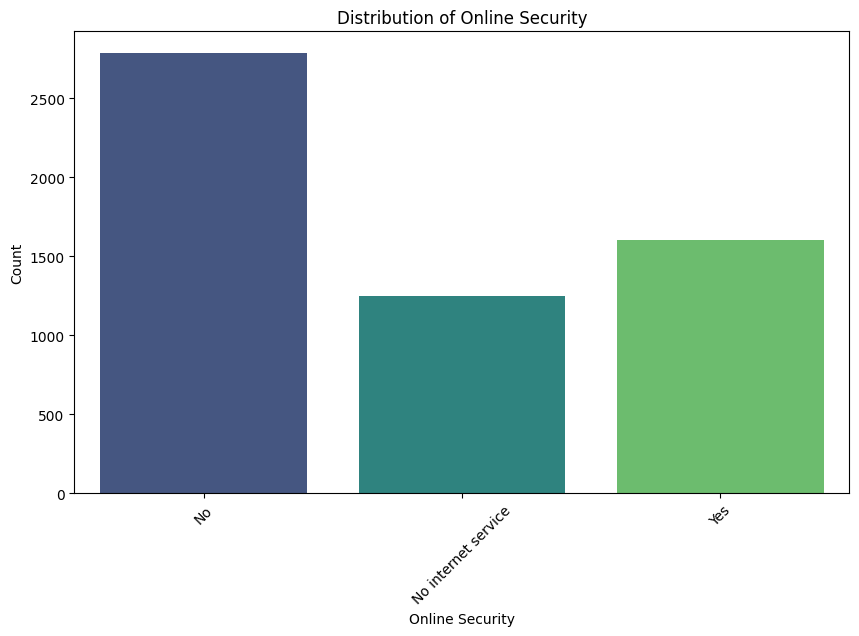

/var/folders/nd/rgq9d99j35x4ykbz3pyy4c2r0000gn/T/ipykernel_11443/3957059429.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=feature, data=X_train, palette='viridis')


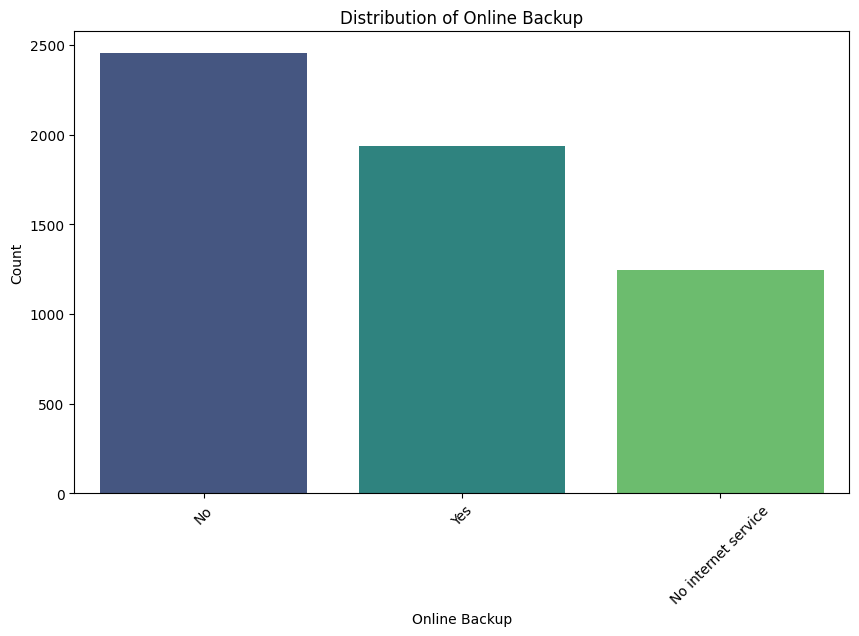

/var/folders/nd/rgq9d99j35x4ykbz3pyy4c2r0000gn/T/ipykernel_11443/3957059429.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=feature, data=X_train, palette='viridis')


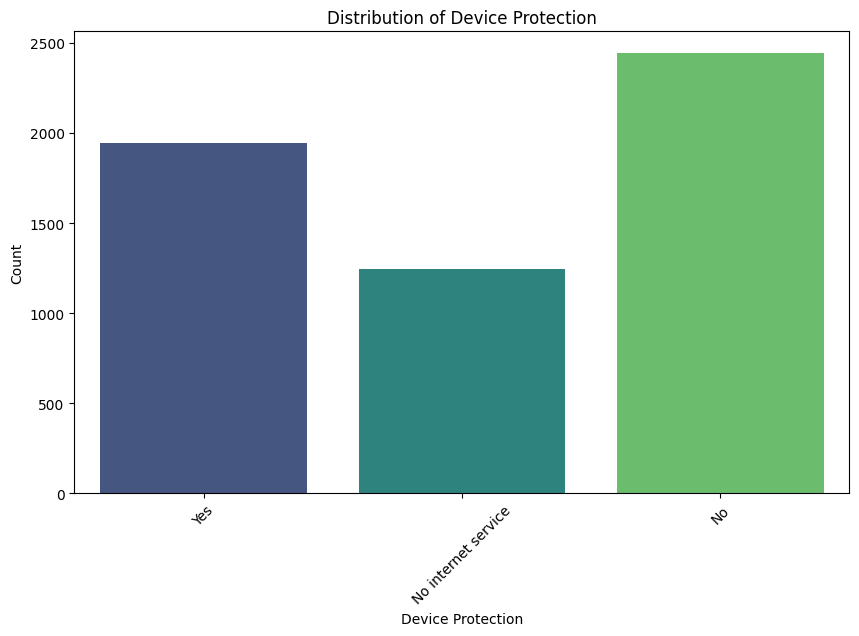

/var/folders/nd/rgq9d99j35x4ykbz3pyy4c2r0000gn/T/ipykernel_11443/3957059429.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=feature, data=X_train, palette='viridis')


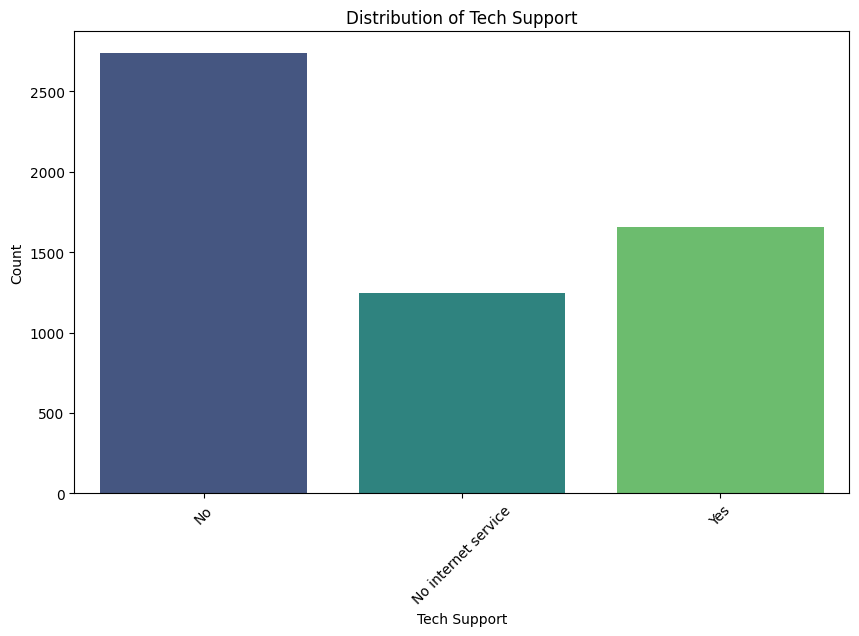

/var/folders/nd/rgq9d99j35x4ykbz3pyy4c2r0000gn/T/ipykernel_11443/3957059429.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=feature, data=X_train, palette='viridis')


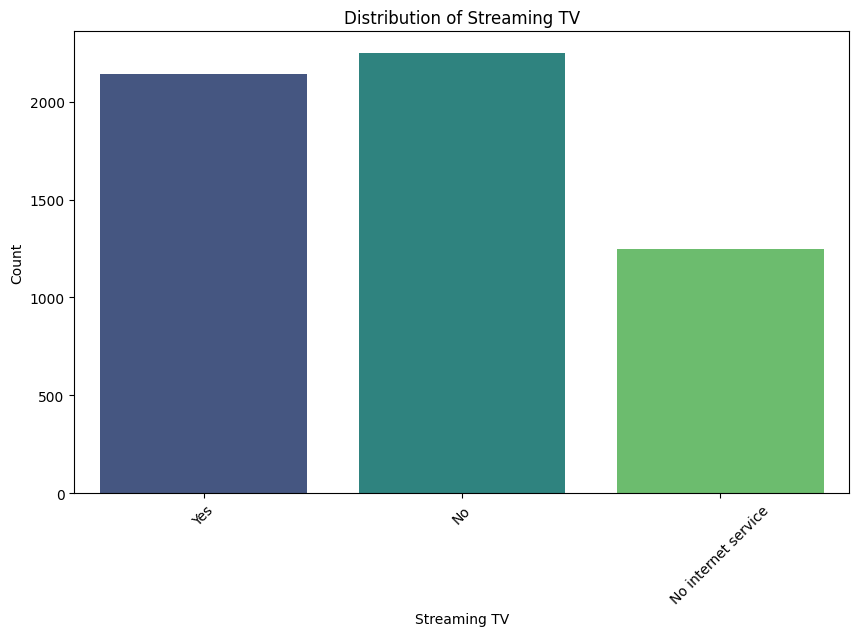

/var/folders/nd/rgq9d99j35x4ykbz3pyy4c2r0000gn/T/ipykernel_11443/3957059429.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=feature, data=X_train, palette='viridis')


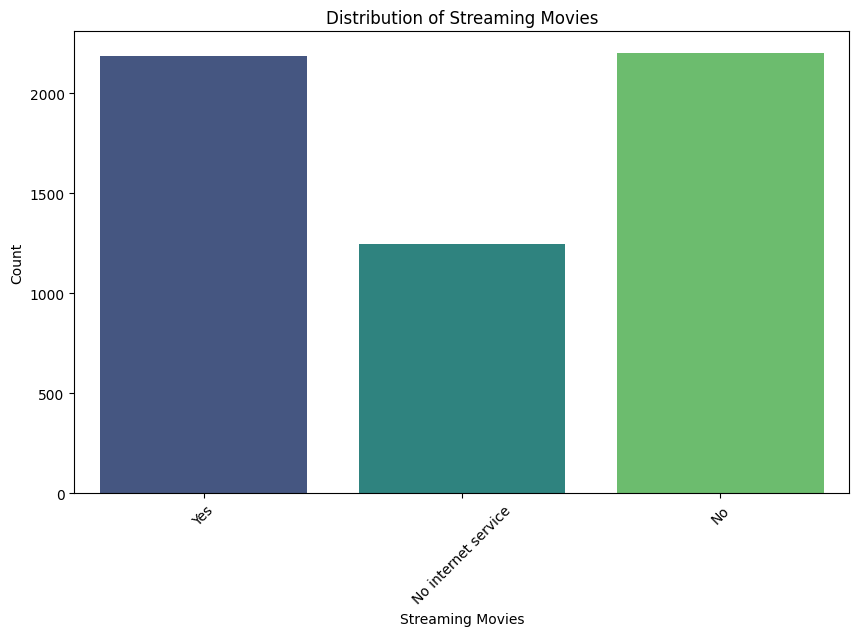

/var/folders/nd/rgq9d99j35x4ykbz3pyy4c2r0000gn/T/ipykernel_11443/3957059429.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=feature, data=X_train, palette='viridis')


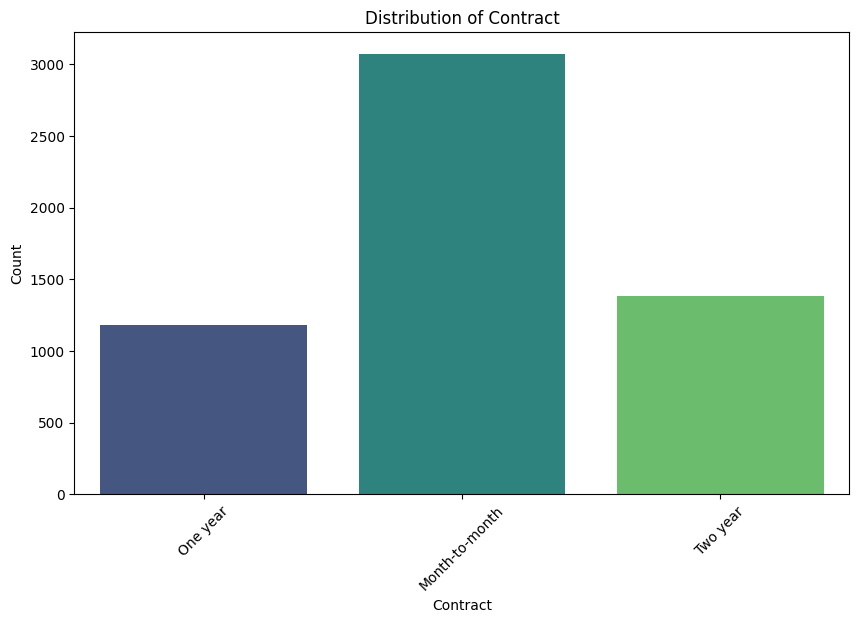

/var/folders/nd/rgq9d99j35x4ykbz3pyy4c2r0000gn/T/ipykernel_11443/3957059429.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=feature, data=X_train, palette='viridis')


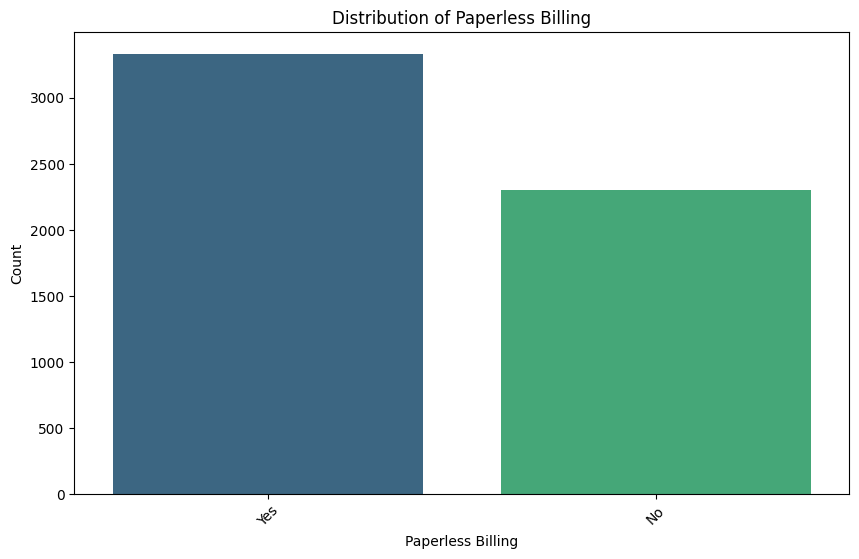

/var/folders/nd/rgq9d99j35x4ykbz3pyy4c2r0000gn/T/ipykernel_11443/3957059429.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=feature, data=X_train, palette='viridis')


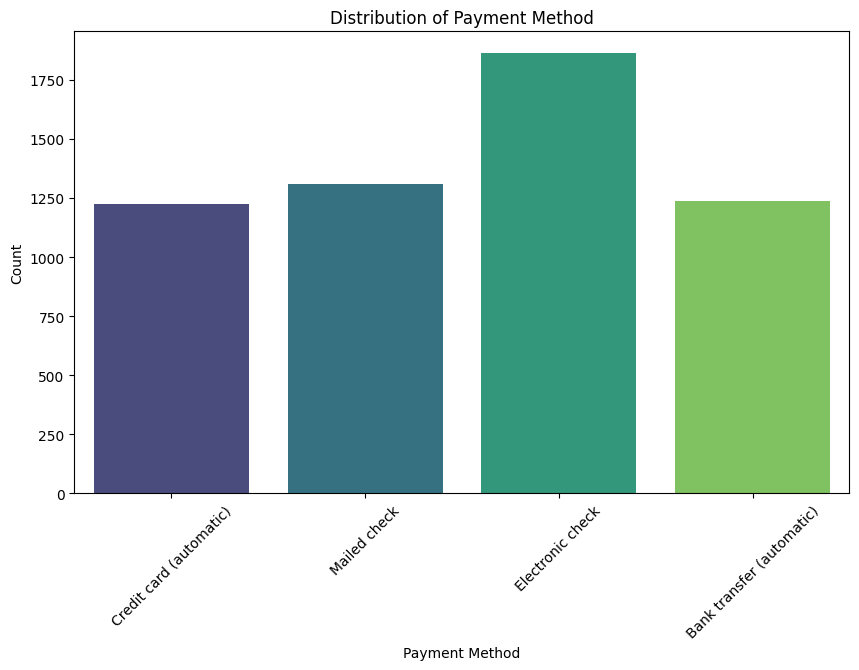

In [31]:
#plot general distribution of categorical features
for feature in cat_features:
    plt.figure(figsize=(10, 6))
    sns.countplot(x=feature, data=X_train, palette='viridis')
    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Count')
    plt.xticks(rotation=45)
    plt.show()



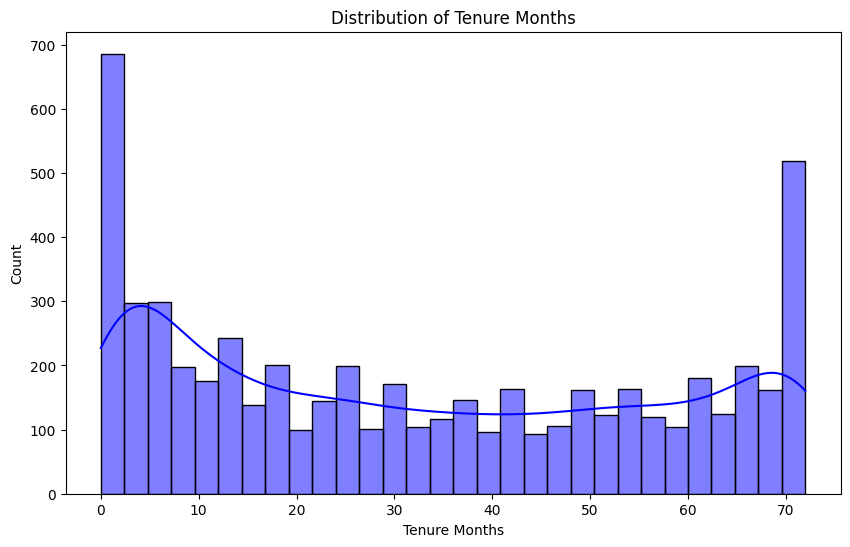

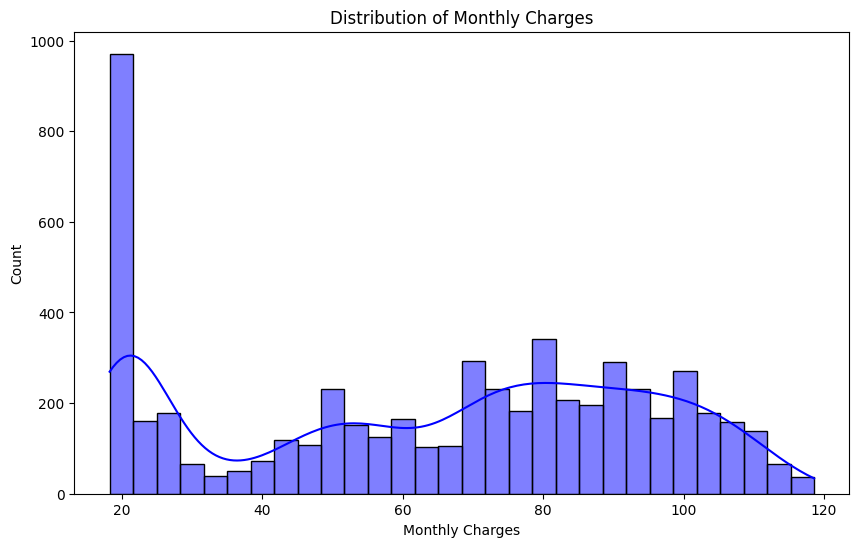

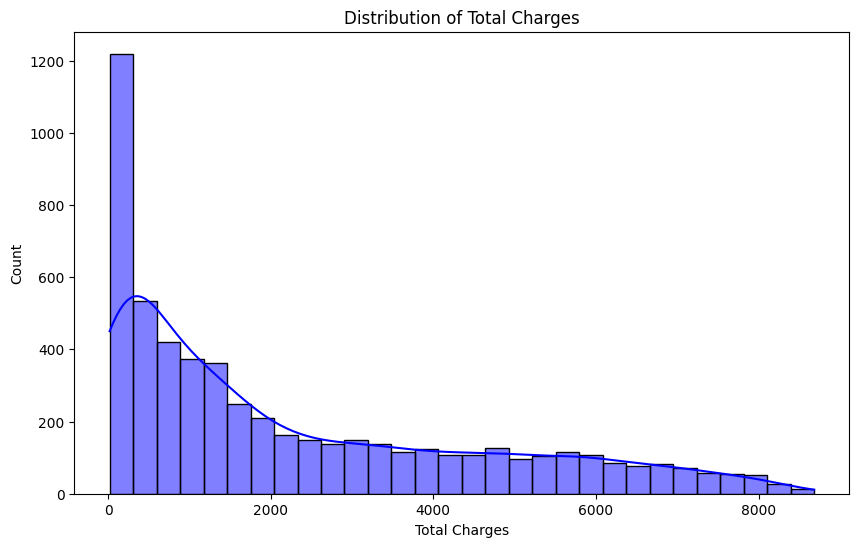

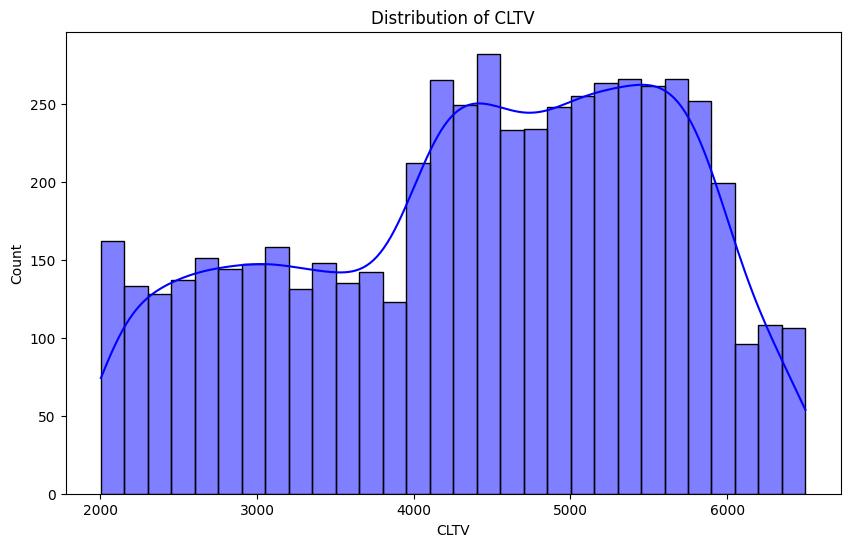

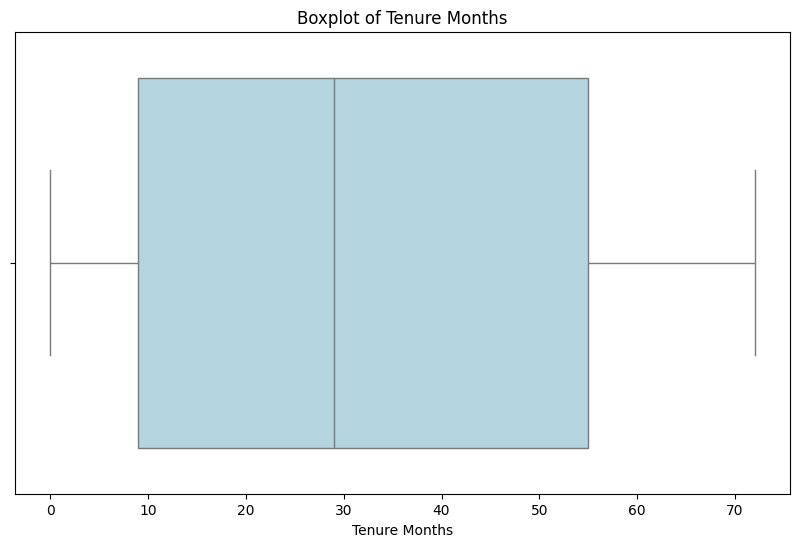

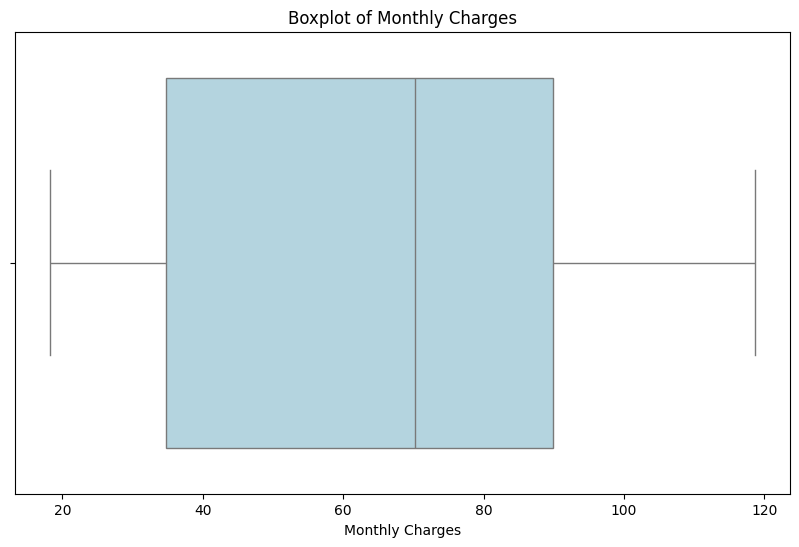

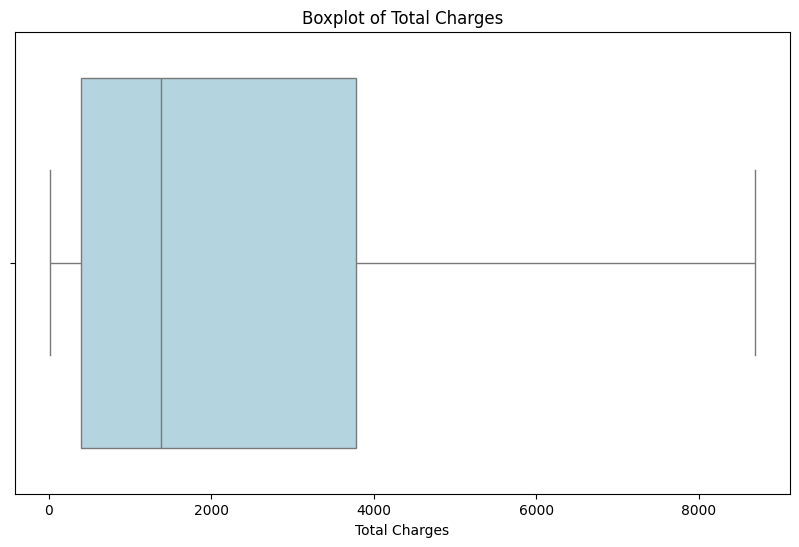

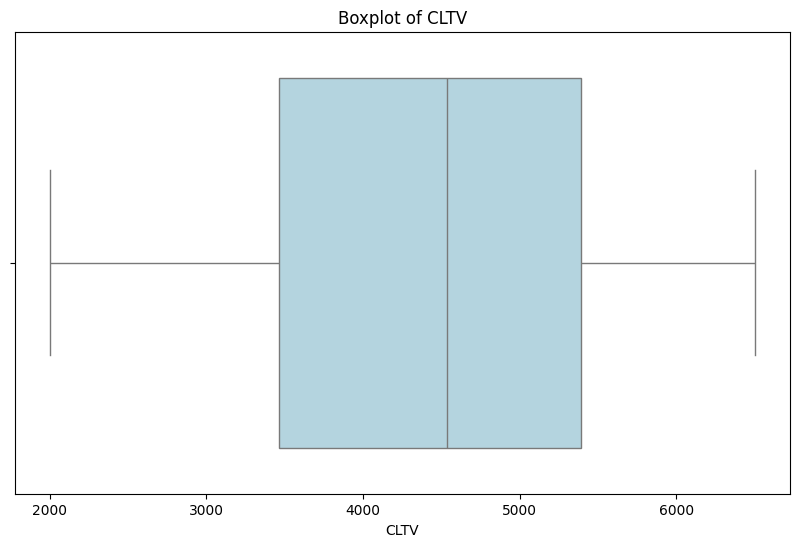

In [35]:
#plot numerical features
for feature in num_features:
    plt.figure(figsize=(10, 6))
    sns.histplot(X_train[feature], bins=30, kde=True, color='blue')
    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Count')
    plt.show()

#boxplot numerical features
for feature in num_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=X_train[feature], color='lightblue')
    plt.title(f'Boxplot of {feature}')
    plt.xlabel(feature)
    plt.show()


In [ ]:
cat_preprocessor = Pipeline(steps=[
    ('most_freq', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
num_preprocessor = Pipeline(steps=[
    
    

Features [1-3]

In [50]:
print(X_train['City'].unique().tolist()) 

['San Diego', 'Jamestown', 'Littlerock', 'El Monte', 'Los Angeles', 'Rio Dell', 'Burson', 'Santa Rosa', 'Malibu', 'Gerber', 'Daggett', 'Penn Valley', 'Sacramento', 'Fulton', 'Green Valley Lake', 'Tarzana', 'San Mateo', 'Klamath', 'West Hills', 'Topanga', 'Marysville', 'Sultana', 'Antelope', 'Camarillo', 'Boulevard', 'Maywood', 'Campo', 'Greenville', 'Mount Laguna', 'Temecula', 'California City', 'Rowland Heights', 'Stockton', 'Sunol', 'Kelseyville', 'Sugarloaf', 'Carmel Valley', 'Los Alamitos', 'Roseville', 'Glendale', 'Woodacre', 'Rancho Palos Verdes', 'Nipomo', 'Stanford', 'Irvine', 'Modesto', 'Agoura Hills', 'Little River', 'Alviso', 'Kenwood', 'Garden Grove', 'Yountville', 'Whittier', 'Bakersfield', 'La Puente', 'Frazier Park', 'Olancha', 'Alta', 'San Geronimo', 'Anaheim', 'Pescadero', 'Rancho Santa Fe', 'Westwood', 'National City', 'Saint Helena', 'Pico Rivera', 'Eureka', 'Ventura', 'Brawley', 'Imperial', 'La Mesa', 'Ben Lomond', 'Courtland', 'Martinez', 'Weldon', 'Redding', 'Moke

In [51]:
len(X_train['City'].unique()) # too many cities,

1129

In [52]:
y_train.value_counts() 

Churn Value
0    4165
1    1469
Name: count, dtype: int64

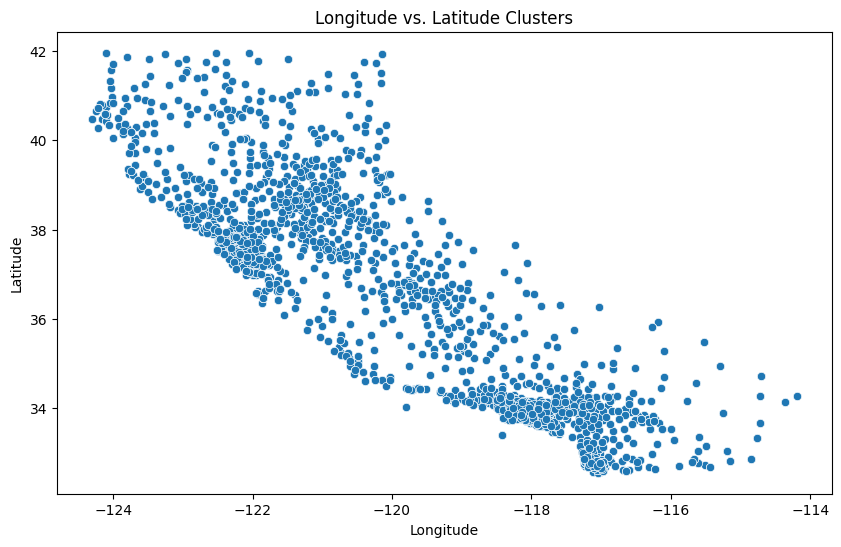

In [53]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Longitude', y='Latitude', data=X_train)
plt.title('Longitude vs. Latitude Clusters')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()
#california state! 

In [ ]:
#pipeline for preprocessing
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

#prerocessing for city : long lat city --> knn
#preprocessing for categorical features : 1 0



